In [1]:
# Univariate and Bivariate EDA

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import f_oneway
base=Path.cwd()
df=pd.read_csv(base/'wine_clean.csv')
X=df.drop(columns='class')
sns.set_theme(style='whitegrid')

In [3]:
#Q1 - Samples per class

class
0    59
1    71
2    48
Name: count, dtype: int64


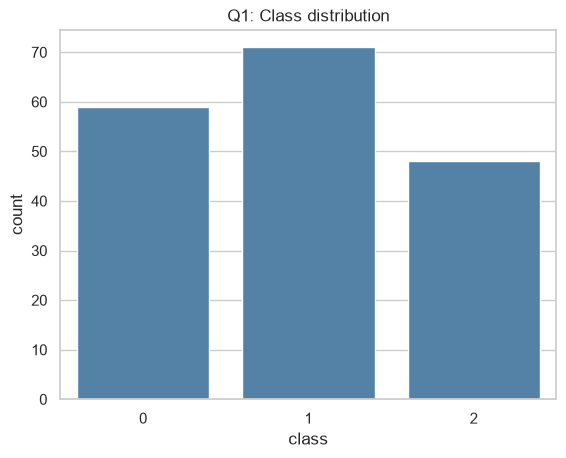

In [4]:
print(df['class'].value_counts().sort_index()); sns.countplot(data=df,x='class',color='steelblue');plt.title('Q1: Class distribution');plt.show()

In [5]:
#Q2 - Descriptive statistics

In [6]:
print(X.agg(['mean','median','std']).T.round(3))

                                 mean   median      std
alcohol                        13.001   13.050    0.812
malic_acid                      2.336    1.865    1.117
ash                             2.367    2.360    0.274
alcalinity_of_ash              19.495   19.500    3.340
magnesium                      99.742   98.000   14.282
total_phenols                   2.295    2.355    0.626
flavanoids                      2.029    2.135    0.999
nonflavanoid_phenols            0.362    0.340    0.124
proanthocyanins                 1.591    1.555    0.572
color_intensity                 5.058    4.690    2.318
hue                             0.957    0.965    0.229
od280/od315_of_diluted_wines    2.612    2.780    0.710
proline                       746.893  673.500  314.907


In [7]:
#Q3 -Alcohol distribution

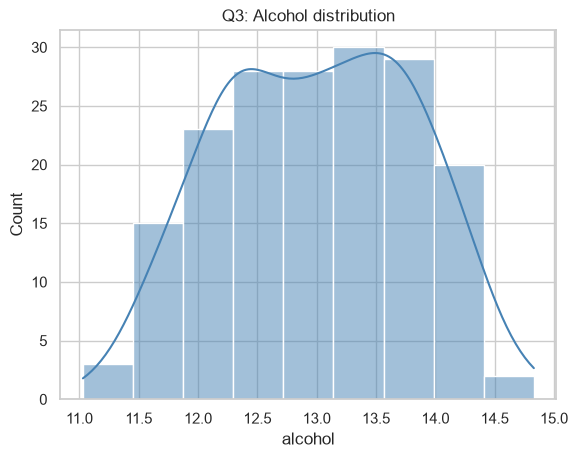

Alcohol skewness: -0.051


In [8]:
sns.histplot(df['alcohol'],kde=True,color='steelblue');plt.title('Q3: Alcohol distribution');plt.show();print('Alcohol skewness:',round(df['alcohol'].skew(),3))

In [9]:
## Q4 - Greatest spread

In [10]:
print('Standard deviation (units differ):\n',X.std().sort_values(ascending=False));print('Relative spread (coefficient of variation):\n',(X.std()/X.mean()).sort_values(ascending=False))

Standard deviation (units differ):
 proline                         314.907474
magnesium                        14.282484
alcalinity_of_ash                 3.339564
color_intensity                   2.318286
malic_acid                        1.117146
flavanoids                        0.998859
alcohol                           0.811827
od280/od315_of_diluted_wines      0.709990
total_phenols                     0.625851
proanthocyanins                   0.572359
ash                               0.274344
hue                               0.228572
nonflavanoid_phenols              0.124453
dtype: float64
Relative spread (coefficient of variation):
 flavanoids                      0.492226
malic_acid                      0.478159
color_intensity                 0.458332
proline                         0.421623
proanthocyanins                 0.359771
nonflavanoid_phenols            0.343933
total_phenols                   0.272689
od280/od315_of_diluted_wines    0.271851
hue              

In [11]:
## Q5 - IQR flags

In [12]:
q1=X.quantile(.25);q3=X.quantile(.75);iqr=q3-q1;print(((X.lt(q1-1.5*iqr))|(X.gt(q3+1.5*iqr))).sum().sort_values(ascending=False))

magnesium                       4
alcalinity_of_ash               4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
nonflavanoid_phenols            0
flavanoids                      0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


In [13]:
## Q6 - Class balance

In [14]:
print((df['class'].value_counts(normalize=True).sort_index()*100).round(1).astype(str)+'%')

class
0    33.1%
1    39.9%
2    27.0%
Name: proportion, dtype: str


In [15]:
## Q7 - Alcohol vs color intensity

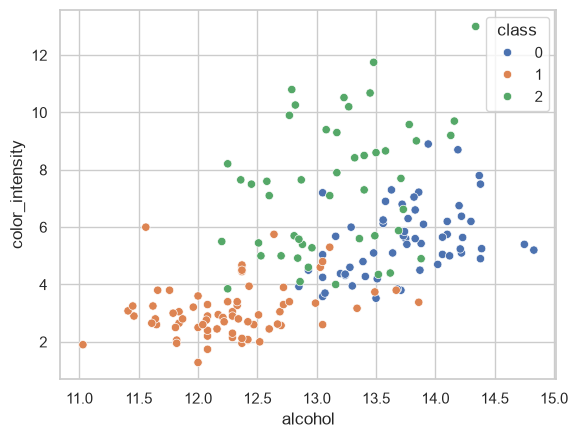

Pearson r: 0.546


In [16]:
sns.scatterplot(data=df,x='alcohol',y='color_intensity',hue='class',palette='deep');plt.show();print('Pearson r:',round(df['alcohol'].corr(df['color_intensity']),3))

In [17]:
## Q8 - Flavanoids vs total phenols

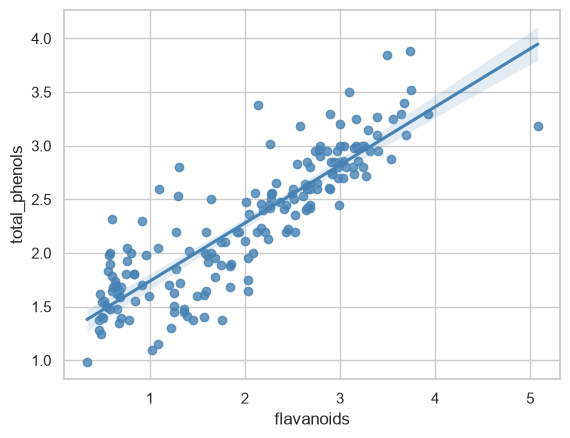

Pearson r: 0.865


In [18]:
sns.regplot(data=df,x='flavanoids',y='total_phenols',color='steelblue');plt.show();print('Pearson r:',round(df['flavanoids'].corr(df['total_phenols']),3))

In [19]:
## Q9 - Proline by class

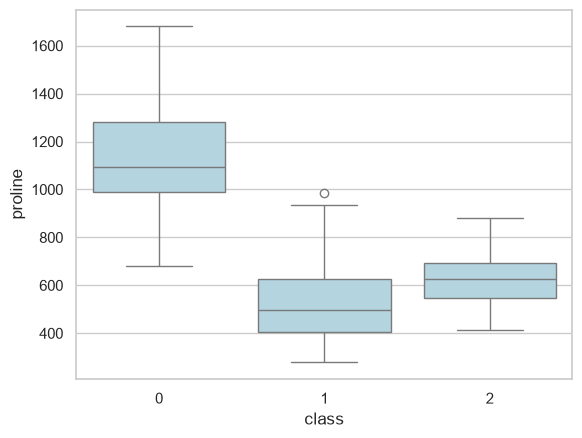

          mean  median     std
class                         
0      1115.71  1095.0  221.52
1       519.51   495.0  157.21
2       629.90   627.5  115.10


In [20]:
sns.boxplot(data=df,x='class',y='proline',color='lightblue');plt.show();print(df.groupby('class')['proline'].agg(['mean','median','std']).round(2))

In [21]:
## Q10 - Alcohol by class

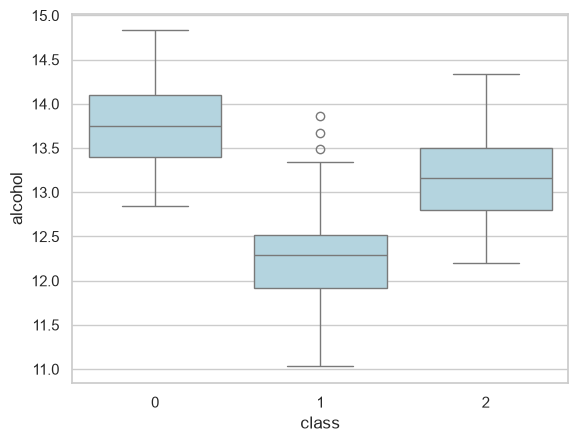

class
0    13.744746
1    12.278732
2    13.153750
Name: alcohol, dtype: float64
One-way ANOVA (exploratory): F_onewayResult(statistic=np.float64(135.07762424279912), pvalue=np.float64(3.319503795619654e-36))


In [22]:
sns.boxplot(data=df,x='class',y='alcohol',color='lightblue');plt.show();print(df.groupby('class')['alcohol'].mean());groups=[g['alcohol'].to_numpy() for _,g in df.groupby('class')];print('One-way ANOVA (exploratory):',f_oneway(*groups))

In [23]:
## Q11 - Feature correlations

Most negative:
 malic_acid            hue                            -0.561296
flavanoids            nonflavanoid_phenols           -0.537900
color_intensity       hue                            -0.521813
nonflavanoid_phenols  od280/od315_of_diluted_wines   -0.503270
total_phenols         nonflavanoid_phenols           -0.449935
dtype: float64
Most positive:
 proline  proanthocyanins                NaN
         color_intensity                NaN
         hue                            NaN
         od280/od315_of_diluted_wines   NaN
         proline                        NaN
dtype: float64


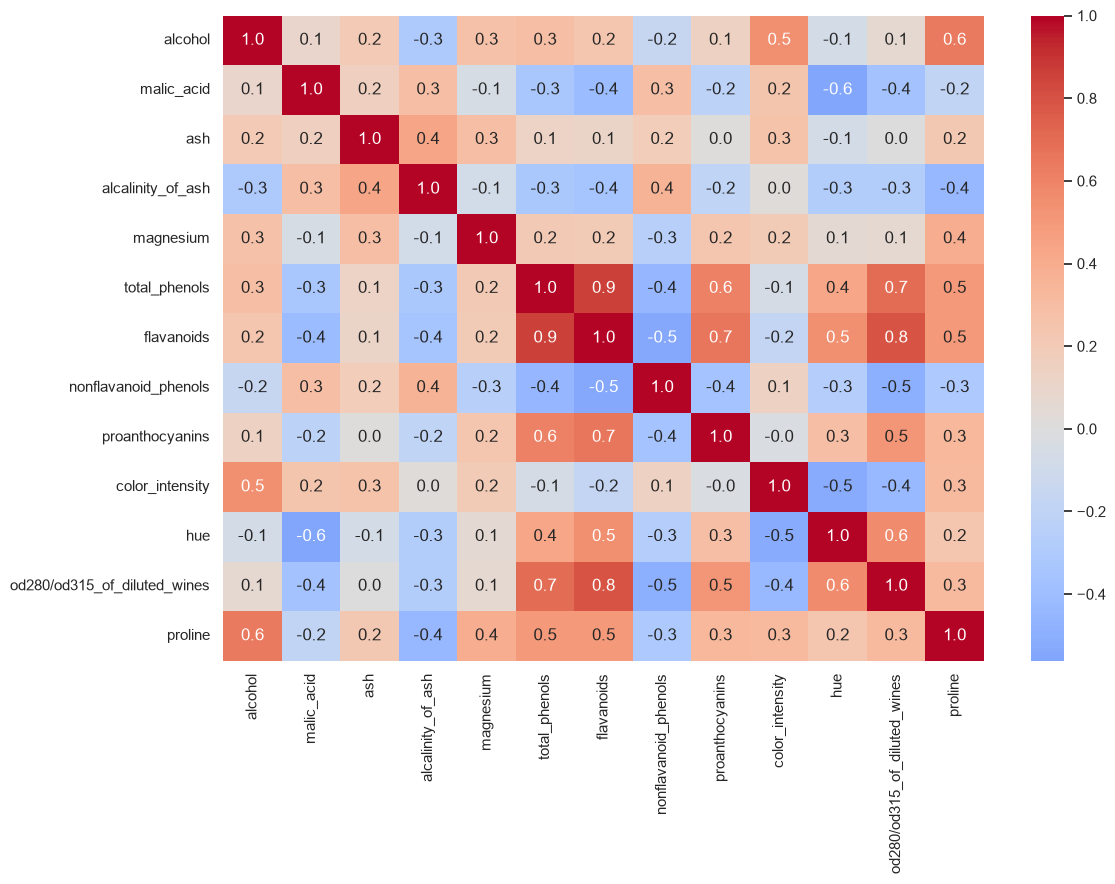

In [24]:
corr=X.corr();pairs=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().sort_values();print('Most negative:\n',pairs.head(5));print('Most positive:\n',pairs.tail(5));plt.figure(figsize=(12,9));sns.heatmap(corr,annot=True,fmt='.1f',cmap='coolwarm',center=0);plt.tight_layout();plt.show()

In [25]:
## Q12 - Alcohol and proline

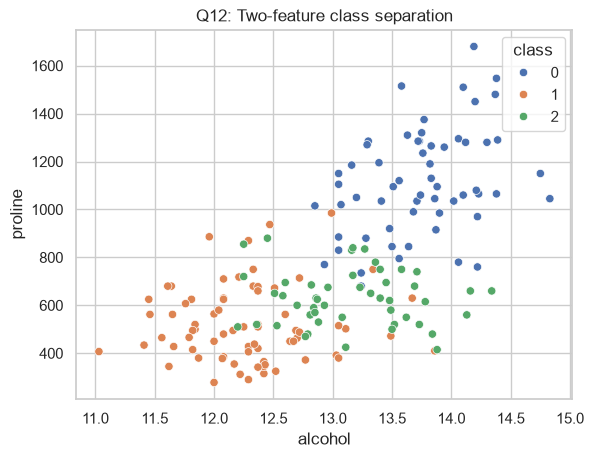

In [26]:
sns.scatterplot(data=df,x='alcohol',y='proline',hue='class',palette='deep');plt.title('Q12: Two-feature class separation');plt.show()

In [27]:
## Q13 - Feature association with class

In [28]:
from sklearn.feature_selection import f_classif; F,p=f_classif(X,df['class']);print(pd.DataFrame({'feature':X.columns,'F_score':F,'p_value':p}).sort_values('F_score',ascending=False).to_string(index=False));print('These are descriptive whole-dataset comparisons only; model selection uses training folds.')

                     feature    F_score      p_value
                  flavanoids 233.925873 3.598586e-50
                     proline 207.920374 5.783168e-47
od280/od315_of_diluted_wines 189.972321 1.393105e-44
                     alcohol 135.077624 3.319504e-36
             color_intensity 120.664018 1.162008e-33
                         hue 101.316795 5.917662e-30
               total_phenols  93.733010 2.137670e-28
                  malic_acid  36.943425 4.127229e-14
           alcalinity_of_ash  35.771637 9.444473e-14
             proanthocyanins  30.271383 5.125359e-12
        nonflavanoid_phenols  27.575417 3.888041e-11
                         ash  13.312901 4.149968e-06
                   magnesium  12.429584 8.963395e-06
These are descriptive whole-dataset comparisons only; model selection uses training folds.
